# Sampling points along a polyline

In [1]:
import cartopy.crs as ccrs
import earthkit.plots as ekp
import numpy as np

from earthkit.geo.distance import haversine_distance
from earthkit.geo.polyline import sample_polyline

## Two waypoints

We sample 10 points on the line from London to New York. The function returns the latitudes and the longitudes (in degrees) of the points. The first and the last point are the waypoints.

In [2]:
wp_lats = [51.51, 40.71]  # London, New York
wp_lons = [-0.13, -74.01]

lats, lons = sample_polyline(wp_lats, wp_lons, n=10)
print("lats:", lats.round(2))
print("lons:", lons.round(2))

lats: [51.51 52.94 53.68 53.7  52.99 51.59 49.57 47.03 44.04 40.71]
lons: [ -0.13  -8.92 -18.16 -27.57 -36.82 -45.63 -53.81 -61.26 -67.97 -74.01]


In [3]:
print("first point is London:  ", (lats[0], lons[0]) == (wp_lats[0], wp_lons[0]))
print("last point is New York: ", (lats[-1], lons[-1]) == (wp_lats[-1], wp_lons[-1]))

first point is London:   True
last point is New York:  True


## Three ways to join two waypoints

The ``method`` argument sets the path between consecutive waypoints:

- ``"great_circle"`` (default): the shortest path on the sphere.
- ``"rhumb"``: a path of constant compass bearing.
- ``"linear"``: a straight line in latitude and longitude.

Here they are on a map with longitude and latitude as the axes. We use 50 points to get smooth lines.

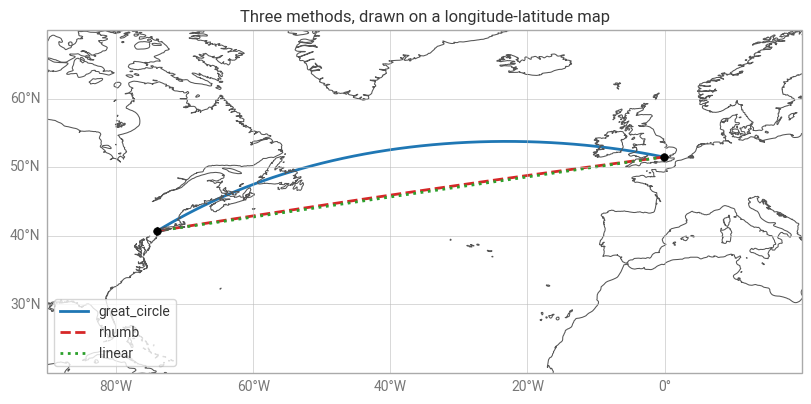

In [4]:
colours = {"great_circle": "tab:blue", "rhumb": "tab:red", "linear": "tab:green"}
styles = {"great_circle": "-", "rhumb": "--", "linear": ":"}
domain = [-90, 20, 20, 70]


def draw(m):
    for method, colour in colours.items():
        lats, lons = sample_polyline(wp_lats, wp_lons, n=50, method=method)
        m.line(lons, lats, label=method, color=colour, linestyle=styles[method], linewidth=2)
    m.scatter(wp_lons, wp_lats, color="k", s=30, zorder=5)
    m.coastlines()
    m.gridlines()


fig = ekp.Figure(rows=1, columns=1, figsize=(8, 5))
m = fig.add_map(domain=domain, crs=ccrs.PlateCarree())
draw(m)
m.legend(loc="lower left")
m.title("Three methods, drawn on a longitude-latitude map")
fig.show()

## Which line is straight depends on the map

Each method gives a line that is straight in a suitable map projection:

- ``"linear"`` is straight on a longitude-latitude map (PlateCarree).
- ``"rhumb"`` is straight on a Mercator map, which keeps compass bearings.
- ``"great_circle"`` is straight on a gnomonic map. Gnomonic is the only projection where all great circles are straight lines. Here it is centred between the two waypoints.

The three maps below show the same three lines. The map extent is set with ``m.ax``, the cartopy axes of the earthkit-plots map. In the first two maps the rhumb line and the linear line are almost on top of each other.

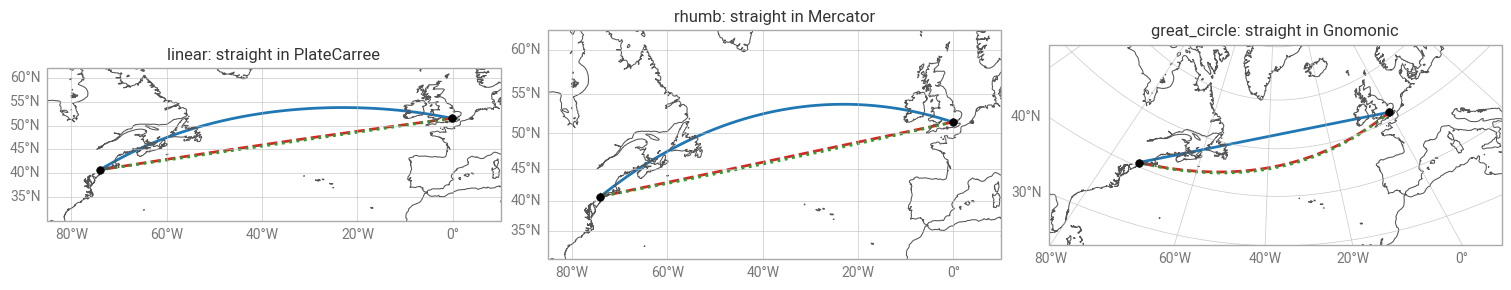

In [5]:
centre_lat = np.mean(wp_lats)
centre_lon = np.mean(wp_lons)

projections = {
    "linear: straight in PlateCarree": ccrs.PlateCarree(),
    "rhumb: straight in Mercator": ccrs.Mercator(),
    "great_circle: straight in Gnomonic": ccrs.Gnomonic(central_latitude=centre_lat, central_longitude=centre_lon),
}

fig = ekp.Figure(rows=1, columns=3, figsize=(15, 5))
for title, crs in projections.items():
    m = fig.add_map(crs=crs)
    draw(m)
    m.ax.set_extent([-85, 10, 30, 62], crs=ccrs.PlateCarree())  # cartopy axes of the map
    m.title(title)
fig.show()

## More than two waypoints

A polyline can have any number of waypoints. Every waypoint is kept exactly as given, and `n` must be at least the number of waypoints. Here are 4 waypoints and 20 points.

In [6]:
cities = ["London", "Cairo", "Delhi", "Singapore"]
wp_lats = [51.51, 30.04, 28.61, 1.35]
wp_lons = [-0.13, 31.24, 77.21, 103.82]

lats, lons = sample_polyline(wp_lats, wp_lons, n=20)

# position of each waypoint in the result
index = [int(np.flatnonzero((lats == la) & (lons == lo))[0]) for la, lo in zip(wp_lats, wp_lons)]
print("indices of the waypoints:", index)

indices of the waypoints: [0, 6, 13, 19]


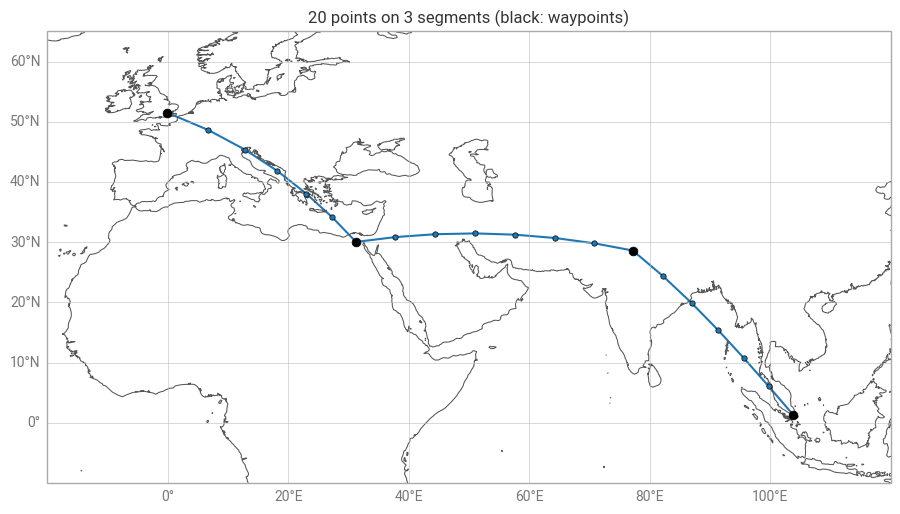

In [7]:
fig = ekp.Figure(rows=1, columns=1, figsize=(9, 5))
m = fig.add_map(domain=[-20, 120, -10, 65], crs=ccrs.PlateCarree())
m.line(lons, lats, color="tab:blue", linewidth=1.5)
m.scatter(lons, lats, color="tab:blue", s=15, zorder=4)
m.scatter(wp_lons, wp_lats, color="k", s=40, zorder=5)
m.coastlines()
m.gridlines()
m.title("20 points on 3 segments (black: waypoints)")
fig.show()

The extra points (`n` minus the number of waypoints) are shared among the segments in proportion to the length of each segment, measured along the chosen path. For ``"great_circle"`` this is the angle between the ends of the segment. The shares are rounded so that the total is exactly `n`. Inside a segment the points are equally spaced along the path.

Below is the number of points added inside each segment and the distance between neighbouring points. The distance is about the same on every segment, but not exactly, because the number of points is a whole number.

In [8]:
extra = np.diff(index) - 1
print("points inside each segment:", extra, "(total", extra.sum(), "= 20 -", len(cities), ")")

# distance in km between neighbouring points
spacing = (
    np.array([haversine_distance((lats[i], lons[i]), (lats[i + 1], lons[i + 1])) for i in range(len(lats) - 1)]) / 1000
)
for i, (start, end) in enumerate(zip(cities[:-1], cities[1:])):
    print(f"{start} -> {end}: {spacing[index[i] : index[i + 1]].round().astype(int)} km")

points inside each segment: [5 6 5] (total 16 = 20 - 4 )
London -> Cairo: [585 585 585 585 585 585] km
Cairo -> Delhi: [633 633 633 633 633 633 633] km
Delhi -> Singapore: [690 690 690 690 690 690] km


## Longitudes and the antimeridian

The interior points of a great circle or rhumb line get longitudes in the range [0, 360) if all the waypoint longitudes are non-negative, and in [-180, 180) otherwise. The waypoints themselves are returned as given.

A great circle from Tokyo to San Francisco crosses the antimeridian (longitude 180°). If we give San Francisco as -122.42° the longitudes jump from about 180° to -180°, and a line drawn through them would cross the whole map:

In [9]:
tokyo = (35.68, 139.69)
san_francisco = (37.77, -122.42)

lats, lons = sample_polyline([tokyo[0], san_francisco[0]], [tokyo[1], san_francisco[1]], n=30)
print(f"longitudes from {lons.min():.1f} to {lons.max():.1f}")
print(f"largest step between neighbouring points: {np.abs(np.diff(lons)).max():.1f} degrees")

longitudes from -178.1 to 178.1
largest step between neighbouring points: 356.2 degrees


If we give San Francisco as 237.58° (the same place, -122.42° + 360°) all the longitudes are non-negative, so the result is in [0, 360) and continuous. We plot it on a map centred on 180° (Robinson projection with ``central_longitude=180``). We do not use a longitude-latitude (PlateCarree) map here, because earthkit-plots wraps longitudes above 180° to [-180, 180) on such maps, which brings the jump back.

In [10]:
lats, lons = sample_polyline([tokyo[0], san_francisco[0]], [tokyo[1], san_francisco[1] + 360], n=30)
print(f"longitudes from {lons.min():.1f} to {lons.max():.1f}")
print(f"largest step between neighbouring points: {np.abs(np.diff(lons)).max():.1f} degrees")

longitudes from 139.7 to 237.6
largest step between neighbouring points: 3.9 degrees


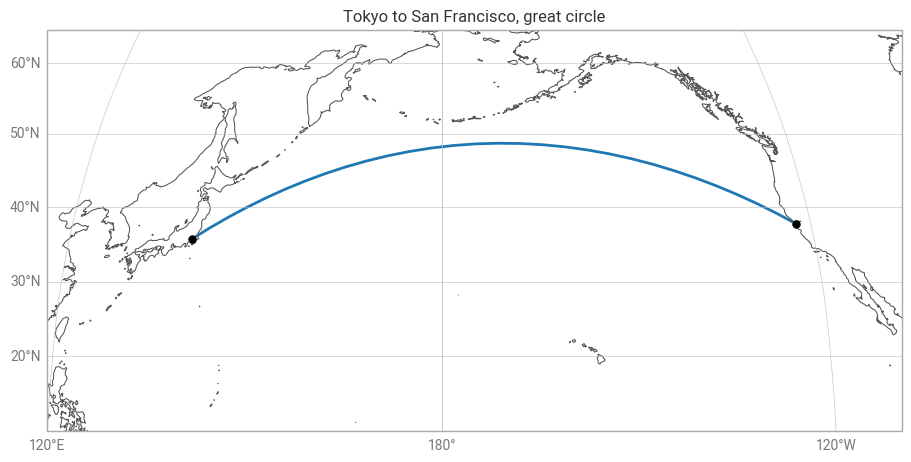

In [11]:
fig = ekp.Figure(rows=1, columns=1, figsize=(9, 5))
m = fig.add_map(domain=[120, 250, 10, 65], crs=ccrs.Robinson(central_longitude=180))
m.line(lons, lats, color="tab:blue", linewidth=2)
m.scatter([lons[0], lons[-1]], [lats[0], lats[-1]], color="k", s=30, zorder=5)
m.coastlines()
m.gridlines()
m.title("Tokyo to San Francisco, great circle")
fig.show()

The ``"rhumb"`` and ``"linear"`` methods take the difference of the longitudes literally, they do not choose the shortest way round. Going from 170° to 190° crosses the antimeridian, but going from 170° to -170° runs the long way, through 0°:

In [12]:
_, lons = sample_polyline([0, 0], [170, 190], n=5, method="linear")
print("[170, 190]: ", lons)

_, lons = sample_polyline([0, 0], [170, -170], n=5, method="linear")
print("[170, -170]:", lons)

[170, 190]:  [170. 175. 180. 185. 190.]
[170, -170]: [ 170.   85.    0.  -85. -170.]


## See also